In [1]:
# ---------------------------------------------------------
# Practical 3C: Energy Consumption Anomaly Detection
# Using LSTM Autoencoder
# ---------------------------------------------------------

# Step 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
# Step 2: Load the dataset

data = pd.read_csv("energy consumption.csv")

print("Dataset Shape:", data.shape)
print("\nFirst five records:")
print(data.head())

Dataset Shape: (5000, 7)

First five records:
          Timestamp  Electricity_Consumed  Temperature  Humidity  Wind_Speed  \
0  01-01-2024 00:00              0.457786     0.469524  0.396368    0.445441   
1  01-01-2024 00:30              0.351956     0.465545  0.451184    0.458729   
2  01-01-2024 01:00              0.482948     0.285415  0.408289    0.470360   
3  01-01-2024 01:30              0.628838     0.482095  0.512308    0.576241   
4  01-01-2024 02:00              0.335974     0.624741  0.672021    0.373004   

   Avg_Past_Consumption  Anomaly_Label  
0              0.692057              0  
1              0.539874              0  
2              0.614724              0  
3              0.757044              0  
4              0.673981              0  


In [3]:
# Step 3: Preprocess the data

# Convert Timestamp into datetime format
data["Timestamp"] = pd.to_datetime(
    data["Timestamp"],
    format="%d-%m-%Y %H:%M"
)

In [4]:
# Sort records according to timestamp
data = data.sort_values("Timestamp").reset_index(drop=True)


In [5]:
# Select input features
features = [
    "Electricity_Consumed",
    "Temperature",
    "Humidity",
    "Wind_Speed",
    "Avg_Past_Consumption"
]

In [6]:
# Fill missing numerical values
data[features] = data[features].interpolate(
    method="linear"
)

data[features] = data[features].ffill().bfill()


In [7]:
# Get actual anomaly labels
labels = data["Anomaly_Label"].values


In [8]:
# Extract numerical feature values
X = data[features].values

print("\nMissing values after preprocessing:")
print(data[features].isnull().sum())


Missing values after preprocessing:
Electricity_Consumed    0
Temperature             0
Humidity                0
Wind_Speed              0
Avg_Past_Consumption    0
dtype: int64


In [9]:
# Step 4: Split data chronologically
# 70% training, 10% validation, 20% testing

n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.80)

X_train_raw = X[:train_end]
y_train_raw = labels[:train_end]

X_val_raw = X[train_end:val_end]
y_val_raw = labels[train_end:val_end]

X_test_raw = X[val_end:]
y_test_raw = labels[val_end:]

In [10]:
# Step 5: Normalize the features

# Fit scaler using only normal training records
normal_train_rows = X_train_raw[y_train_raw == 0]

scaler = MinMaxScaler()

scaler.fit(normal_train_rows)

X_train_scaled = scaler.transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

In [11]:
# Step 6: Create time windows

# Each window contains 24 consecutive readings
TIME_STEPS = 24

def create_windows(X, y, time_steps):

    X_windows = []
    y_windows = []

    for i in range(len(X) - time_steps + 1):

        # Take 24 consecutive readings
        X_windows.append(
            X[i:i + time_steps]
        )

        # Window is anomalous if any reading is anomalous
        y_windows.append(
            int(np.max(y[i:i + time_steps]) == 1)
        )

    return np.array(X_windows), np.array(y_windows)

In [12]:
# Create training windows
X_train_windows, y_train_windows = create_windows(
    X_train_scaled,
    y_train_raw,
    TIME_STEPS
)

In [13]:
# Create validation windows
X_val_windows, y_val_windows = create_windows(
    X_val_scaled,
    y_val_raw,
    TIME_STEPS
)


In [14]:
# Create testing windows
X_test_windows, y_test_windows = create_windows(
    X_test_scaled,
    y_test_raw,
    TIME_STEPS
)


In [15]:
# Keep only completely normal windows for training
X_train_normal = X_train_windows[
    y_train_windows == 0
]

In [17]:
# Keep only normal windows for validation
X_val_normal = X_val_windows[
    y_val_windows == 0
]

print("\nTraining window shape:", X_train_normal.shape)
print("Validation window shape:", X_val_normal.shape)
print("Testing window shape:", X_test_windows.shape)



Training window shape: (1515, 24, 5)
Validation window shape: (254, 24, 5)
Testing window shape: (977, 24, 5)


In [18]:
# Step 7: Build LSTM Autoencoder

input_shape = (
    TIME_STEPS,
    len(features)
)

model = keras.Sequential([

    # Encoder
    layers.Input(shape=input_shape),

    layers.LSTM(
        64,
        activation="tanh",
        return_sequences=True
    ),

    layers.LSTM(
        32,
        activation="tanh",
        return_sequences=False
    ),

    # Repeat compressed representation
    layers.RepeatVector(TIME_STEPS),

    # Decoder
    layers.LSTM(
        32,
        activation="tanh",
        return_sequences=True
    ),

    layers.LSTM(
        64,
        activation="tanh",
        return_sequences=True
    ),

    # Reconstruct original features
    layers.TimeDistributed(
        layers.Dense(len(features))
    )
])

In [19]:
# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 24, 64)              │          17,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          12,416 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 24, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 24, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 24, 64)              │          24,832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 24, 5)               │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 63,813 (249.27 KB)

 Trainable params: 63,813 (249.27 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Step 8: Compile the model

model.compile(
    optimizer="adam",
    loss="mse"
)

In [21]:
# Step 9: Train the model

history = model.fit(
    X_train_normal,
    X_train_normal,

    epochs=20,
    batch_size=64,

    validation_data=(
        X_val_normal,
        X_val_normal
    ),

    shuffle=True
)

Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 11s 88ms/step - loss: 0.1034 - val_loss: 0.0435
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 0.0383 - val_loss: 0.0337
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0315 - val_loss: 0.0298
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - loss: 0.0285 - val_loss: 0.0281
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0270 - val_loss: 0.0268
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.0263 - val_loss: 0.0263
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0258 - val_loss: 0.0268
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0253 - val_loss: 0.0250
Epoch 9/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 0.0243 - val_loss: 0.0245
Epoch 10/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.0237 - val_loss: 0.0243
Epoch 11/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.0235 - val_loss: 0.0242
Epoch 12/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - loss: 0.

In [22]:
# Step 10: Calculate reconstruction error
# Use normal validation data to set threshold

val_reconstructed = model.predict(X_val_normal)

val_errors = np.mean(
    np.square(X_val_normal - val_reconstructed),
    axis=(1, 2)
)


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 148ms/step


In [23]:
# Set threshold at 99th percentile
threshold = np.percentile(val_errors, 99)

print("\nReconstruction Error Threshold:", threshold)


Reconstruction Error Threshold: 0.03594539406901898


In [24]:
# Step 11: Detect anomalies in test data

test_reconstructed = model.predict(X_test_windows)

test_errors = np.mean(
    np.square(X_test_windows - test_reconstructed),
    axis=(1, 2)
)

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


In [25]:
# Error greater than threshold means anomaly
y_pred = (test_errors > threshold).astype(int)

In [26]:
print(y_pred)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 1 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 

In [27]:
# Step 12: Evaluate the model

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_windows, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test_windows,
        y_pred,
        zero_division=0
    )
)

print("Precision:", precision_score(
    y_test_windows, y_pred, zero_division=0
))

print("Recall:", recall_score(
    y_test_windows, y_pred, zero_division=0
))

print("F1 Score:", f1_score(
    y_test_windows, y_pred, zero_division=0
))


Confusion Matrix:
[[484   0]
 [471  22]]

Classification Report:
              precision    recall  f1-score   support

           0       0.51      1.00      0.67       484
           1       1.00      0.04      0.09       493

    accuracy                           0.52       977
   macro avg       0.75      0.52      0.38       977
weighted avg       0.76      0.52      0.38       977

Precision: 1.0
Recall: 0.04462474645030426
F1 Score: 0.0854368932038835


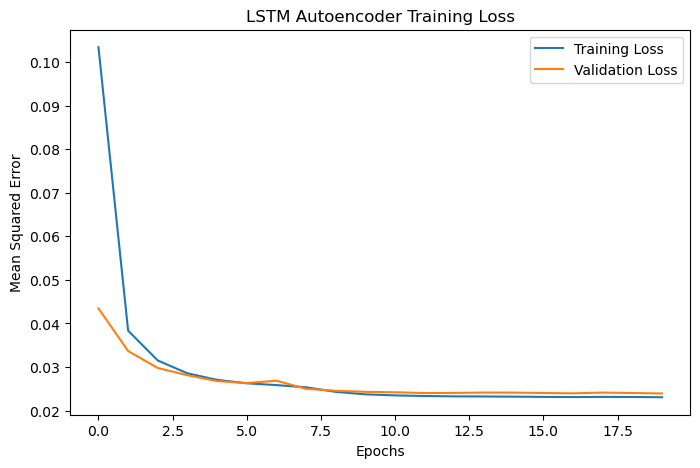

In [28]:
# Step 13: Plot training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.show()


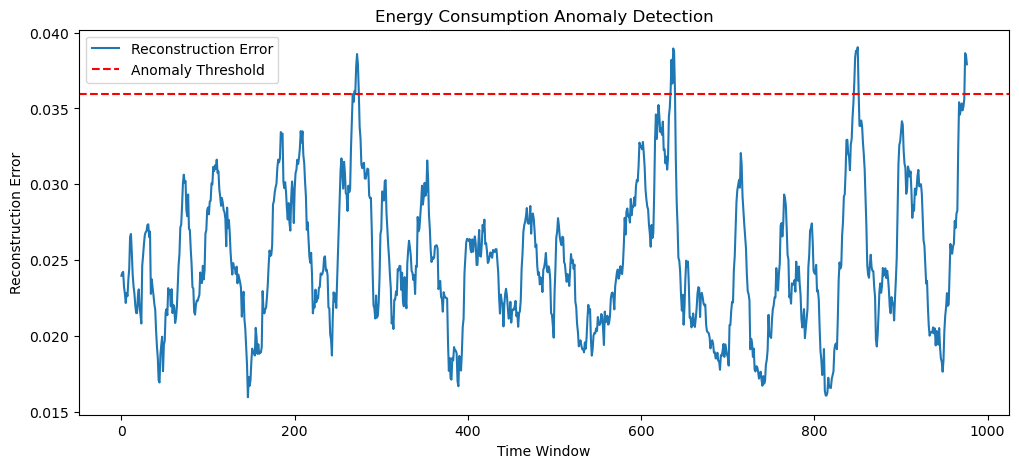

In [30]:

# Step 14: Plot reconstruction errors and threshold

plt.figure(figsize=(12, 5))

plt.plot(
    test_errors,
    label="Reconstruction Error"
)

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.title("Energy Consumption Anomaly Detection")
plt.xlabel("Time Window")
plt.ylabel("Reconstruction Error")
plt.legend()
plt.show()



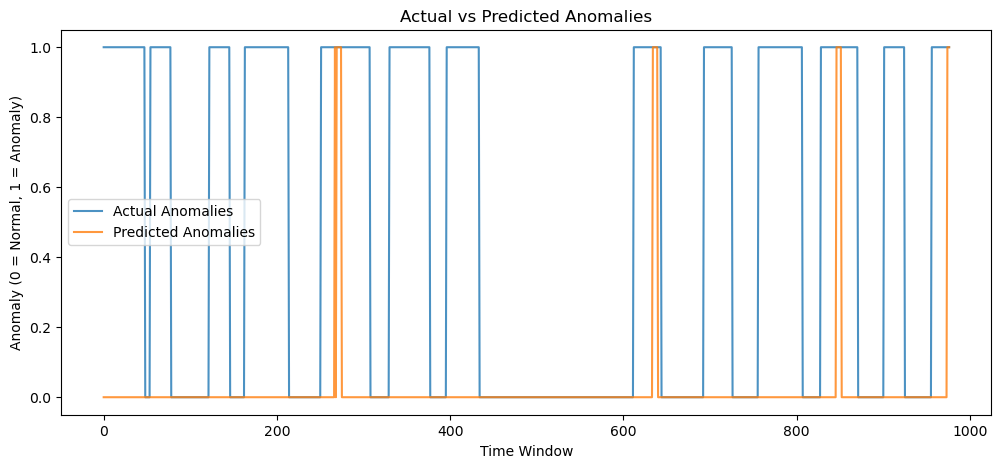

In [31]:
# Step 15: Compare actual and predicted anomalies

plt.figure(figsize=(12, 5))

plt.plot(
    y_test_windows,
    label="Actual Anomalies",
    alpha=0.8
)

plt.plot(
    y_pred,
    label="Predicted Anomalies",
    alpha=0.8
)

plt.title("Actual vs Predicted Anomalies")
plt.xlabel("Time Window")
plt.ylabel("Anomaly (0 = Normal, 1 = Anomaly)")
plt.legend()
plt.show()

In [32]:
# Step 16: Display anomaly detection result

print("\nTotal Test Windows:", len(y_test_windows))
print("Actual Anomalous Windows:", np.sum(y_test_windows))
print("Predicted Anomalous Windows:", np.sum(y_pred))

print("\nPractical Completed Successfully!")



Total Test Windows: 977
Actual Anomalous Windows: 493
Predicted Anomalous Windows: 22

Practical Completed Successfully!
